In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

In [24]:
PROC=Path("../data/processed")
FIG=Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
id_cols=["admission_type_id","discharge_disposition_id","admission_source_id"]
dt={c: str for c in id_cols}

train=pd.read_csv(PROC/"train.csv",keep_default_na=False,dtype=dt)
test=pd.read_csv(PROC/"test.csv",keep_default_na=False,dtype=dt)


In [25]:
target="readmit_30"
X_train,y_train=train.drop(columns=[target]),train[target]
X_test,y_test=test.drop(columns=[target]),test[target]

In [26]:
pipe=joblib.load("../models/best_pipeline.joblib")

In [27]:
print("Test:",X_test.shape," positive rate:",y_test.mean().round(4))
print("Model:",type(pipe.named_steps["model"]).__name__)

Test: (13998, 50)  positive rate: 0.0898
Model: RandomForestClassifier


In [28]:
THRESHOLD = 0.437

In [29]:
proba=pipe.predict_proba(X_test)[:,1]
pred=(proba>=THRESHOLD).astype(int)

roc=roc_auc_score(y_test,proba)
ap=average_precision_score(y_test,proba)

print(f"ROC-AUC:{roc:.3f}")
print(f"PR-AUC:{ap:.3f} (random guessing = {y_test.mean():.3f})")
print(f"At threshold {THRESHOLD:.3f}:")
print(f"Recall:{recall_score(y_test, pred):.3f}")
print(f"Precision:{precision_score(y_test, pred):.3f}")
print(f"Flagged:{pred.mean():.1%} of patients")

ROC-AUC:0.658
PR-AUC:0.179 (random guessing = 0.090)
At threshold 0.437:
Recall:0.511
Precision:0.149
Flagged:30.9% of patients


In [30]:
rng=np.random.default_rng(42)
n=len(y_test)
y_arr=y_test.to_numpy()
rocs,aps=[],[]

for _ in range(1000):
    idx=rng.integers(0,n,n)
    if y_arr[idx].sum()==0:
        continue
    rocs.append(roc_auc_score(y_arr[idx],proba[idx]))
    aps.append(average_precision_score(y_arr[idx],proba[idx]))

print(f"ROC-AUC 95% CI: {np.percentile(rocs, [2.5,97.5]).round(3)}")
print(f"PR-AUC  95% CI: {np.percentile(aps, [2.5,97.5]).round(3)}")

ROC-AUC 95% CI: [0.642 0.675]
PR-AUC  95% CI: [0.161 0.198]


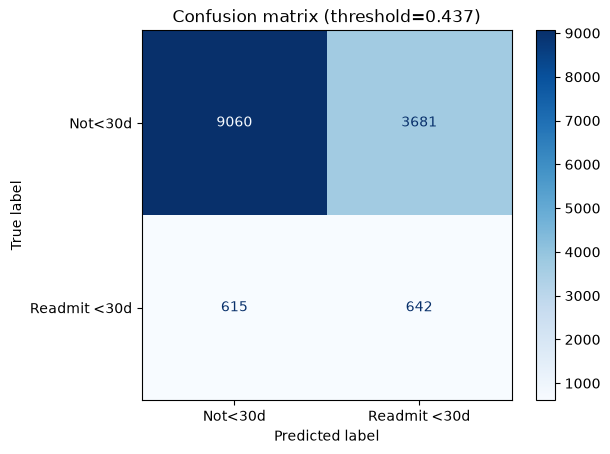

Caught 642 of 1257 readmissions; 3681 false alarms for 642 true hits (about 5.7 false alarms per hit)


In [31]:
cm=confusion_matrix(y_test,pred)
ConfusionMatrixDisplay(cm,display_labels=["Not<30d","Readmit <30d"]).plot(
    cmap="Blues",values_format="d")
plt.title(f"Confusion matrix (threshold={THRESHOLD:.3f})")
plt.savefig(FIG/"confusion_matrix.png",dpi=150,bbox_inches="tight")
plt.show()

tn,fp,fn,tp=cm.ravel()
print(f"Caught {tp} of {tp+fn} readmissions; "
      f"{fp} false alarms for {tp} true hits "
      f"(about {fp/max(tp,1):.1f} false alarms per hit)")

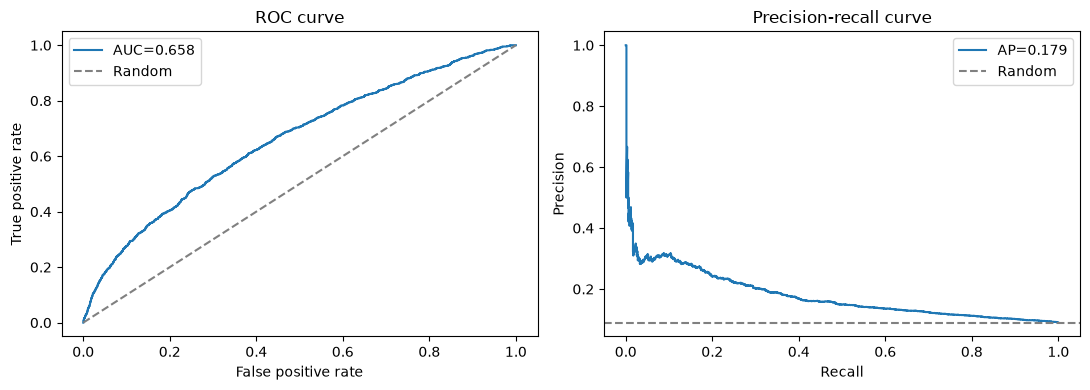

In [32]:
fpr,tpr,_=roc_curve(y_test,proba)
prec,rec,_=precision_recall_curve(y_test,proba)

fig,ax=plt.subplots(1,2,figsize=(11,4))

ax[0].plot(fpr,tpr,label=f"AUC={roc:.3f}")
ax[0].plot([0,1],[0,1],"--",color="gray",label="Random")
ax[0].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC curve")
ax[0].legend()

ax[1].plot(rec,prec,label=f"AP={ap:.3f}")
ax[1].axhline(y_test.mean(),ls="--",color="gray",label="Random")
ax[1].set(xlabel="Recall",ylabel="Precision",title="Precision-recall curve")
ax[1].legend()

plt.tight_layout()
plt.savefig(FIG/"roc_pr_test.png",dpi=150,bbox_inches="tight")
plt.show()

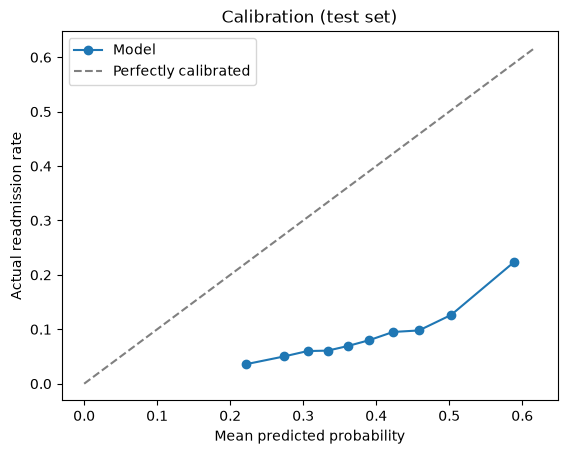

In [33]:
frac_pos,mean_pred=calibration_curve(y_test,proba,n_bins=10,strategy="quantile")

plt.plot(mean_pred,frac_pos,"o-",label="Model")
lim = max(mean_pred.max(),frac_pos.max())*1.05
plt.plot([0,lim],[0,lim],"--",color="gray",label="Perfectly calibrated")
plt.xlabel("Mean predicted probability")
plt.ylabel("Actual readmission rate")
plt.title("Calibration (test set)")
plt.legend()
plt.savefig(FIG/"calibration.png",dpi=150,bbox_inches="tight")
plt.show()

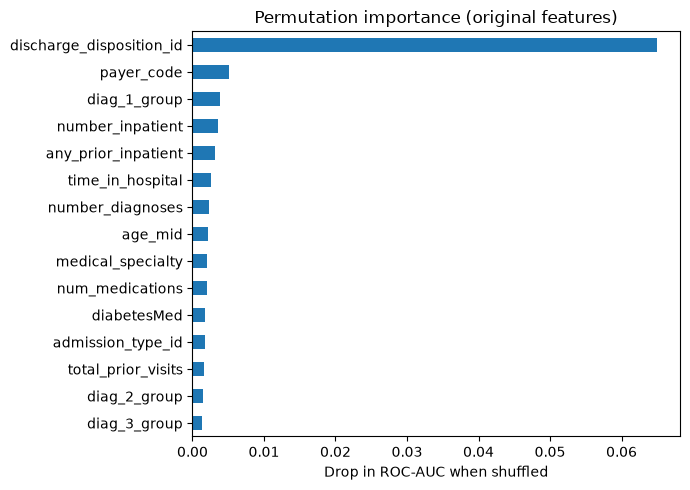

In [34]:
perm=permutation_importance(pipe,X_test,y_test,scoring="roc_auc",
                              n_repeats=5,random_state=42,n_jobs=1)

imp=(pd.Series(perm.importances_mean,index=X_test.columns)
         .sort_values(ascending=False))

imp.head(15)[::-1].plot(kind="barh",figsize=(7, 5))
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Permutation importance (original features)")
plt.tight_layout()
plt.savefig(FIG/"permutation_importance.png",dpi=150,bbox_inches="tight")
plt.show()

In [35]:
print(imp.head(15).to_string())

discharge_disposition_id    0.064928
payer_code                  0.005141
diag_1_group                0.003806
number_inpatient            0.003638
any_prior_inpatient         0.003153
time_in_hospital            0.002650
number_diagnoses            0.002320
age_mid                     0.002102
medical_specialty           0.002050
num_medications             0.001980
diabetesMed                 0.001794
admission_type_id           0.001723
total_prior_visits          0.001619
diag_2_group                0.001403
diag_3_group                0.001318


100%|===================| 598/600 [02:14<00:00]        

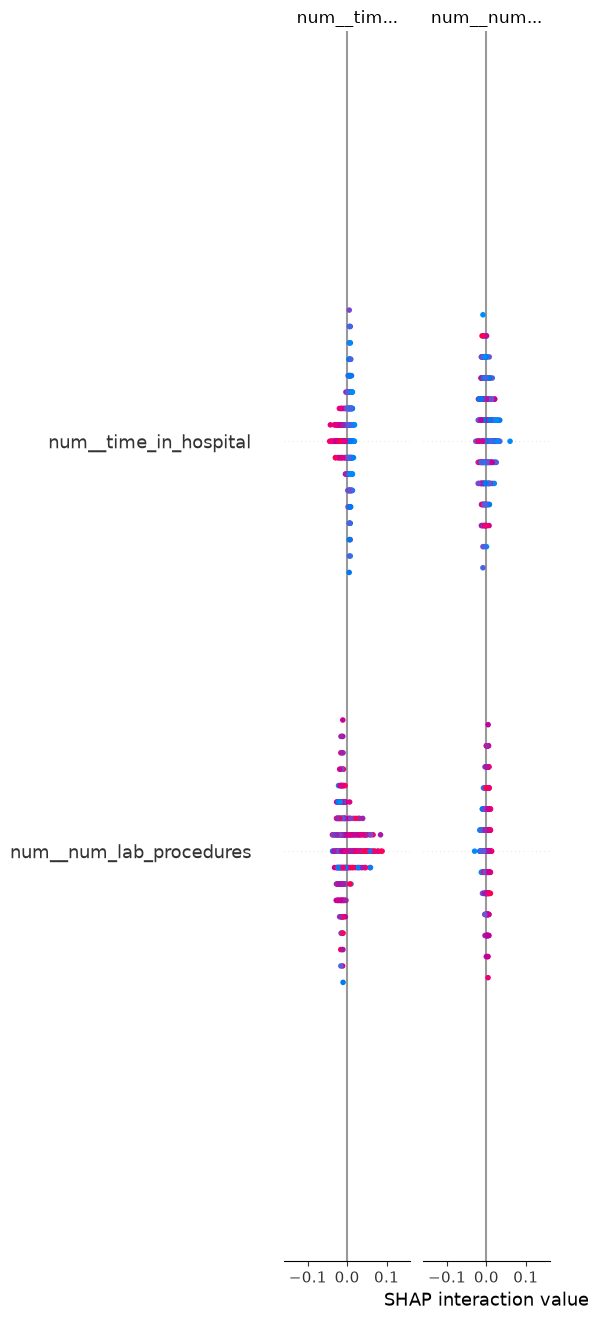

In [36]:
import shap

prep=pipe.named_steps["prep"]
model=pipe.named_steps["model"]
feat_names=prep.get_feature_names_out()

Xt_train=prep.transform(X_train)
Xt_test=prep.transform(X_test)

rng=np.random.default_rng(42)

bg=Xt_train[rng.choice(len(Xt_train),100,replace=False)]
sample=Xt_test[rng.choice(len(Xt_test),300,replace=False)]


explainer=shap.TreeExplainer(model,data=bg,feature_perturbation="interventional",
                             model_output="probability")


sv=explainer(sample)

shap.summary_plot(sv,sample,feature_names=feat_names,max_display=15,show=False)

plt.savefig(FIG/"shap_summary.png",dpi=150,bbox_inches="tight")
plt.show()


In [37]:
shap_importance=(pd.Series(np.abs(sv.values[:,:,1]).mean(axis=0),index=feat_names).sort_values(ascending=False))

print(shap_importance.head(15).to_string())

cat__discharge_disposition_id_1     0.037323
num__age_mid                        0.012463
num__any_prior_inpatient            0.010766
num__time_in_hospital               0.010557
num__total_prior_visits             0.010052
num__number_inpatient               0.009616
cat__diag_1_group_Circulatory       0.007359
num__number_diagnoses               0.007110
cat__payer_code_Missing             0.007011
num__meds_per_day                   0.006954
cat__discharge_disposition_id_22    0.006511
cat__discharge_disposition_id_3     0.006463
num__num_medications                0.006140
num__num_lab_procedures             0.005032
cat__diabetesMed_Yes                0.004269


In [38]:
final=pd.DataFrame([{"model":type(model).__name__,"threshold":THRESHOLD,
    "roc_auc":roc,"pr_auc":ap,
    "recall":recall_score(y_test,pred),
    "precision":precision_score(y_test,pred),
    "flagged_share":pred.mean(),
}]).round(3)

final.to_csv("../reports/test_results.csv",index=False)
final

,model,threshold,roc_auc,pr_auc,recall,precision,flagged_share
0,RandomForestClassifier,0.437,0.658,0.179,0.511,0.149,0.309


## Final Evaluation Summary

- The test set was evaluated once; the classification threshold was selected beforehand using out-of-fold training predictions.
- **ROC-AUC:** 0.658 (95% CI: *to be filled from bootstrap results*), **PR-AUC:** 0.179 (random baseline ≈ 0.09).
- At threshold **0.437**: recall **0.511**, precision **0.149**, and **30.9%** of patients were flagged.
- Approximately **5.7 false alarms per true readmission caught**.
- Predicted probabilities are not calibrated (class weights may affect their probability estimates); therefore, they should primarily be interpreted as ranking scores rather than reliable absolute risk estimates.
- **Top drivers:** *to be filled using permutation importance / SHAP results*.
- Test performance agrees closely with cross-validation: CV ROC-AUC **0.654** and PR-AUC **0.171**, compared with test ROC-AUC **0.658** and PR-AUC **0.179**.
